## Step 1: Solve an ODE with a PINN

**Problem** ($x \in (0,1)$)

$$u'(x) + u(x) = \sin k x, \qquad u(0) = 1$$

**Exact solution:** $u(x) = \frac{1+k+k^2}{1+k^2} e^{-x} + \frac{\sin (kx) - k\cos(kx)}{1+k^2}$

---

## PINN idea

1. Use a neural network $u_\theta(x)$ as the approximate solution  
2. Minimize the PDE residual $|u' + u - \sin(kx)|^2$ at **collocation points**  
3. Minimize $|u(0)-1|^2$ at the **boundary** $x=0$  
4. Compute $u'$ with PyTorch **automatic differentiation** (`autograd`)

Loss: $\mathcal{L} = \mathcal{L}_{\mathrm{PDE}} + \lambda_{\mathrm{BC}} \mathcal{L}_{\mathrm{BC}}$

Run the cells from top to bottom.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

def set_seed(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)

class MLP(nn.Module):
    """input x -> output u all-to-all (Tanh activation)"""
    def __init__(self, d_in=1, d_out=1, width=32, depth=4):
        super().__init__()
        layers = [nn.Linear(d_in, width), nn.Tanh()]
        for _ in range(depth - 1):
            layers += [nn.Linear(width, width), nn.Tanh()]
        layers.append(nn.Linear(width, d_out))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

def grad(y, x):
    """dy/dx (autograd)"""
    return torch.autograd.grad(
        y, x,
        grad_outputs=torch.ones_like(y),
        create_graph=True,
        retain_graph=True,
    )[0]

def relative_l2(pred, ref):
    return np.linalg.norm(pred - ref) / (np.linalg.norm(ref) + 1e-12)

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cpu


## Hyperparameters

| Symbol | Meaning |
|------|------|
| `K` | Wave number $k$ in $\sin(kx)$ |
| `N_COLLOC` | Number of interior (PDE) points |
| `W_BC` | Weight of boundary loss $\lambda_{\mathrm{BC}}$ |
| `EPOCHS` | Number of training epochs |

If training is unstable, a common fix is to **increase `W_BC`**.

In [14]:
X_MIN, X_MAX = 0.0, 1.0
K = 30.0
N_COLLOC = 200
EPOCHS = 10000
LR = 1e-3
W_BC = 100.0

def exact_u(x, k=K):
    """u(x) = ((1+k+k^2) e^{-x} + sin(kx) - k cos(kx)) / (1+k^2)"""
    denom = 1.0 + k**2
    return ((1.0 + k + k**2) / denom) * np.exp(-x) + (np.sin(k * x) - k * np.cos(k * x)) / denom

## Training loop

- `x_int`: Points where the PDE residual is evaluated (`requires_grad=True` is required)
- `res = du_dx + u_int - sin(K * x_int)`: Residual of $u'+u=\sin(kx)$

In [15]:
model = MLP(width=32, depth=4).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

x_int = torch.linspace(X_MIN + 1e-3, X_MAX, N_COLLOC, device=device).view(-1, 1)
x_int.requires_grad_(True)
x0 = torch.zeros(1, 1, device=device)
u0_target = torch.ones(1, 1, device=device)

x_plot = torch.linspace(X_MIN, X_MAX, 300, device=device).view(-1, 1)
snap_epochs = {0, 100, 500, 1000, 2000, EPOCHS}

def snapshot():
    with torch.no_grad():
        return model(x_plot).detach().cpu().numpy().ravel().copy()

history = []
snapshots = {0: snapshot()}  # untrained network
for epoch in range(EPOCHS):
    optimizer.zero_grad()

    u_int = model(x_int)
    du_dx = grad(u_int, x_int)
    res = du_dx + u_int - torch.sin(K * x_int)
    loss_pde = torch.mean(res ** 2)

    u0 = model(x0)
    loss_bc = torch.mean((u0 - u0_target) ** 2)

    loss = loss_pde + W_BC * loss_bc
    loss.backward()
    optimizer.step()
    history.append(loss.item())

    if (epoch + 1) in snap_epochs:
        snapshots[epoch + 1] = snapshot()
    if (epoch + 1) % 1000 == 0:
        print(
            f"epoch {epoch+1:5d}  loss={loss.item():.3e}  "
            f"pde={loss_pde.item():.3e}  bc={loss_bc.item():.3e}"
        )

epoch  1000  loss=4.907e-01  pde=4.907e-01  bc=1.162e-09
epoch  2000  loss=4.871e-01  pde=4.871e-01  bc=5.784e-09
epoch  3000  loss=3.841e-01  pde=3.841e-01  bc=1.191e-09
epoch  4000  loss=3.011e-01  pde=3.011e-01  bc=2.818e-07
epoch  5000  loss=1.969e-01  pde=1.934e-01  bc=3.451e-05
epoch  6000  loss=1.656e-01  pde=1.656e-01  bc=1.393e-08
epoch  7000  loss=1.253e-01  pde=1.252e-01  bc=6.481e-07
epoch  8000  loss=6.351e-02  pde=6.191e-02  bc=1.603e-05
epoch  9000  loss=5.011e-03  pde=5.009e-03  bc=2.016e-08
epoch 10000  loss=2.330e-03  pde=2.330e-03  bc=7.518e-12


## Visualize results and evaluate error

relative L2 error (k=30): 1.0930e-03


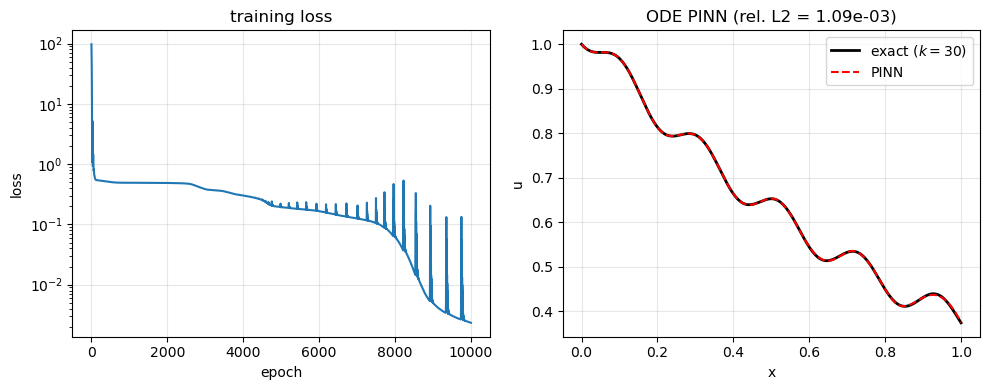

In [16]:
x_test = np.linspace(X_MIN, X_MAX, 300)
x_t = torch.tensor(x_test, dtype=torch.float32, device=device).view(-1, 1)
with torch.no_grad():
    u_pred = model(x_t).cpu().numpy().ravel()
u_ref = exact_u(x_test)
err = relative_l2(u_pred, u_ref)
print(f"relative L2 error (k={K:g}): {err:.4e}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].semilogy(history)
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("loss")
axes[0].set_title("training loss")
axes[0].grid(True, alpha=0.3)

axes[1].plot(x_test, u_ref, "k-", lw=2, label=rf"exact ($k={K:g}$)")
axes[1].plot(x_test, u_pred, "r--", lw=1.5, label="PINN")
axes[1].set_xlabel("x")
axes[1].set_ylabel("u")
axes[1].set_title(f"ODE PINN (rel. L2 = {err:.2e})")
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Exercises (optional)

1. Change `W_BC` to `10` or `500` and observe how the solution changes  
2. Error when `EPOCHS` is reduced to `1000`  
3. Continue to the next notebook `02_poisson_1d_pinn.ipynb` (elliptic PDE, second derivatives)

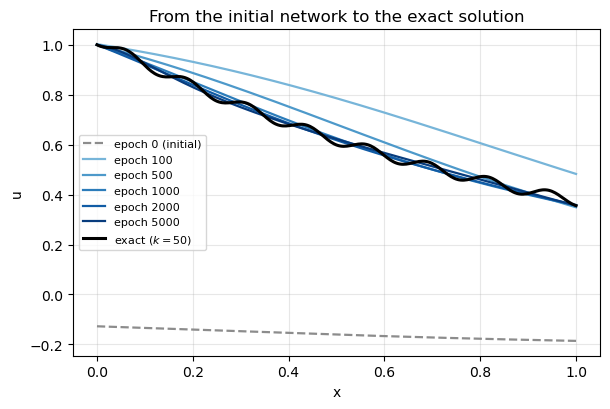

In [10]:
x_snap = x_plot.detach().cpu().numpy().ravel()
u_exact = exact_u(x_snap)
epochs_sorted = sorted(snapshots)

fig, ax = plt.subplots(figsize=(6.2, 4.2))
colors = plt.cm.Blues(np.linspace(0.35, 0.95, len(epochs_sorted)))
for color, ep in zip(colors, epochs_sorted):
    if ep == 0:
        ax.plot(x_snap, snapshots[ep], color="0.55", ls="--", lw=1.6, label="epoch 0 (initial)")
    else:
        ax.plot(x_snap, snapshots[ep], color=color, lw=1.6, label=f"epoch {ep}")
ax.plot(x_snap, u_exact, "k-", lw=2.2, label=rf"exact ($k={K:g}$)")
ax.set_xlabel("x")
ax.set_ylabel("u")
ax.set_title("From the initial network to the exact solution")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Warm start from a good initial solution

For large $k$, the fast oscillation is small. Balancing $u'\approx\sin(kx)$ and $u(0)=1$ gives the approximate initial guess

$$u_{\mathrm{guess}}(x)=e^{-x}+\frac{1-\cos(kx)}{k}+\frac{\sin(kx)}{k^{2}}.$$

The remaining error is a smooth $O(1/k)$ correction. Train only that correction,

$$u_\theta(x)=u_{\mathrm{guess}}(x)+x\,v_\theta(x),$$

with the last layer of $v_\theta$ set to zero. Epoch 0 is exactly $u_{\mathrm{guess}}$, and $u(0)=1$ stays true because of the factor $x$.

epoch     0  rel L2=4.7686e-02  (initial guess)
epoch   100  pde=4.730e-01  rel L2=3.6044e-02
epoch   500  pde=1.126e-03  rel L2=8.1949e-04
epoch  1000  pde=3.114e-04  rel L2=1.1232e-03
plain PINN  rel L2=1.0930e-03  after 10000 epochs
warm start  rel L2=1.1232e-03  after 1000 epochs


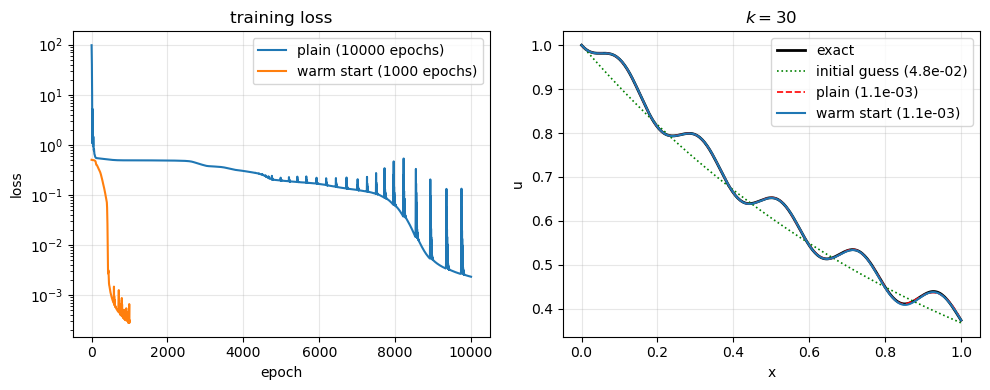

In [20]:
def u_guess(x):
    """Initial guess for large k. Satisfies u(0)=1, but it is not exact."""
    return (
        torch.exp(-x)
        #+ (1.0 - torch.cos(K * x)) / K
        #+ torch.sin(K * x) / K**2
    )

set_seed(42)
corr = MLP(width=32, depth=4).to(device)
nn.init.zeros_(corr.net[-1].weight)
nn.init.zeros_(corr.net[-1].bias)
opt_corr = torch.optim.Adam(corr.parameters(), lr=LR)

x_corr = torch.linspace(X_MIN + 1e-3, X_MAX, N_COLLOC, device=device).view(-1, 1)
x_corr.requires_grad_(True)

WARM_EPOCHS = 1000
history_warm = []
x_eval = torch.tensor(
    np.linspace(X_MIN, X_MAX, 300), dtype=torch.float32, device=device
).view(-1, 1)
ref_eval = exact_u(x_eval.detach().cpu().numpy().ravel())

def rel_warm():
    with torch.no_grad():
        pred = (u_guess(x_eval) + x_eval * corr(x_eval)).cpu().numpy().ravel()
    return relative_l2(pred, ref_eval)

print(f"epoch {0:5d}  rel L2={rel_warm():.4e}  (initial guess)")
for epoch in range(WARM_EPOCHS):
    opt_corr.zero_grad()
    u = u_guess(x_corr) + x_corr * corr(x_corr)
    du_dx = grad(u, x_corr)
    loss_pde = torch.mean((du_dx + u - torch.sin(K * x_corr)) ** 2)
    loss_pde.backward()
    opt_corr.step()
    history_warm.append(loss_pde.item())
    if (epoch + 1) in (100, 500, 1000):
        print(
            f"epoch {epoch+1:5d}  pde={loss_pde.item():.3e}  "
            f"rel L2={rel_warm():.4e}"
        )

with torch.no_grad():
    u_warm = (u_guess(x_eval) + x_eval * corr(x_eval)).cpu().numpy().ravel()
    u_plain = model(x_eval).cpu().numpy().ravel()
x_np = x_eval.detach().cpu().numpy().ravel()
err_plain = relative_l2(u_plain, ref_eval)
err_warm = relative_l2(u_warm, ref_eval)
print(f"plain PINN  rel L2={err_plain:.4e}  after {EPOCHS} epochs")
print(f"warm start  rel L2={err_warm:.4e}  after {WARM_EPOCHS} epochs")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].semilogy(history, label=f"plain ({EPOCHS} epochs)")
axes[0].semilogy(history_warm, label=f"warm start ({WARM_EPOCHS} epochs)")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("loss")
axes[0].set_title("training loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# プロット: 初期値も描画
with torch.no_grad():
    u_init = u_guess(x_eval).cpu().numpy().ravel()
err_init = relative_l2(u_init, ref_eval)

axes[1].plot(x_np, ref_eval, "k-", lw=2, label="exact")
axes[1].plot(x_np, u_init, "g:", lw=1.2, label=f"initial guess ({err_init:.1e})")
axes[1].plot(x_np, u_plain, "r--", lw=1.2, label=f"plain ({err_plain:.1e})")
axes[1].plot(x_np, u_warm, "C0-", lw=1.5, label=f"warm start ({err_warm:.1e})")
axes[1].set_xlabel("x")
axes[1].set_ylabel("u")
axes[1].set_title(rf"$k={K:g}$")
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
# Exact solution function (from the equation in the tex context):
# u(x) = ((1+k+k^2)/(1+k^2)) * exp(-x) + (sin(kx) - k*cos(kx))/(1+k^2)
def u_exact(x, k):
    return ((1 + k + k**2) / (1 + k**2)) * np.exp(-x) + (np.sin(k*x) - k * np.cos(k*x)) / (1 + k**2)

# Example usage/evaluation (optional cell usage if wanted):
# x_plot = np.linspace(0, 1, 100)
# k_val = 5   # or any value you solved with above
# exact_vals = u_exact(x_plot, k_val)
# plt.plot(x_plot, exact_vals, label="Exact solution")
# plt.legend()
# plt.show()